In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

## 1. Check GPU Availability and Dataset Structure

This cell checks whether a GPU is available and displays its name.

It then searches `/kaggle/input` for a dataset containing both `train/images` and `train/labels`. For each matching dataset, it prints the root path and counts the image files in the `train`, `val`, and `test_US` folders.

If an image folder is missing, it displays `Folder not found`.

This check confirms the available hardware and dataset paths before preparing the training sample.

In [1]:
from pathlib import Path
import torch

print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

roots = [
    p.parent.parent
    for p in Path("/kaggle/input").rglob("train/images")
    if (p.parent.parent / "train/labels").is_dir()
]

for root in roots:
    print("\nDataset path:", root)
    for split in ["train", "val", "test_US"]:
        folder = root / split / "images"
        print(
            split,
            sum(1 for p in folder.iterdir() if p.is_file())
            if folder.is_dir() else "Folder not found"
        )

GPU available: True
GPU: Tesla T4

Dataset path: /kaggle/input/datasets/sarvii7/roadscan-yolo/RoadScan_yolo
train 21041
val 1977
test_US 4805


## 2. Prepare the Training Sample

We select 200 training images from each country: Japan, India, and Czech.

Each country contributes 170 images with damage annotations and 30 images with empty labels, giving 600 training images in total. A fixed random seed of 42 reproduces the baseline selection when the source files are unchanged.

All 1,977 validation images from China are copied separately. The US test set remains untouched.

The selected filenames are saved, and a YAML configuration is created for YOLO training.

In [2]:
from pathlib import Path
import random
import shutil

SRC = Path("/kaggle/input/datasets/sarvii7/roadscan-yolo/RoadScan_yolo")
DST = Path("/kaggle/working/sample600")

rng = random.Random(42)
countries = ["Japan", "India", "Czech"]
chosen = []

# Check destination folders before copying.
for split in ["train", "val"]:
    for kind in ["images", "labels"]:
        folder = DST / split / kind
        folder.mkdir(parents=True, exist_ok=True)
        assert not any(folder.iterdir()), (
            f"{folder} is not empty. Stop here to avoid mixing samples."
        )

# Match the baseline's sorted file order and sampling procedure.
images = sorted(p.name for p in (SRC / "train/images").iterdir())

for country in countries:
    pool = [
        name[:-4]
        for name in images
        if name.startswith(country + "_") and name.endswith(".jpg")
    ]

    full, empty = [], []

    for stem in pool:
        label = SRC / "train/labels" / f"{stem}.txt"
        assert label.is_file(), f"Missing label: {label}"
        (full if label.stat().st_size > 0 else empty).append(stem)

    assert len(full) >= 170 and len(empty) >= 30, (
        f"Not enough images for {country}: "
        f"{len(full)} with damage, {len(empty)} empty"
    )

    chosen += rng.sample(full, 170) + rng.sample(empty, 30)
    print(f"{country} | with damage: 170 | empty: 30")

# Copy the selected training images and labels.
for stem in chosen:
    for kind, extension in [("images", ".jpg"), ("labels", ".txt")]:
        shutil.copy2(
            SRC / "train" / kind / f"{stem}{extension}",
            DST / "train" / kind / f"{stem}{extension}",
        )

# Copy all validation images and their matching labels.
val_images = sorted((SRC / "val/images").glob("*.jpg"))

for image in val_images:
    label = SRC / "val/labels" / f"{image.stem}.txt"
    assert label.is_file(), f"Missing label: {label}"

    shutil.copy2(image, DST / "val/images" / image.name)
    shutil.copy2(label, DST / "val/labels" / label.name)

# Save the sample list and YOLO configuration.
Path("/kaggle/working/sample600_list.txt").write_text(
    "\n".join(sorted(chosen)), encoding="utf-8"
)

yaml_path = Path("/kaggle/working/data.yaml")
yaml_path.write_text(
    f"""path: {DST}
train: train/images
val: val/images
names:
  0: D00
  1: D10
  2: D20
  3: D40
""",
    encoding="utf-8",
)

print(f"\ntrain: {len(chosen)} | val: {len(val_images)}")
print("YOLO configuration:", yaml_path)

Japan | with damage: 170 | empty: 30
India | with damage: 170 | empty: 30
Czech | with damage: 170 | empty: 30

train: 600 | val: 1977
YOLO configuration: /kaggle/working/data.yaml


## 3. Install Ultralytics and Check the Environment

This step installs Ultralytics, imports YOLO, and displays the Ultralytics and PyTorch versions.

It also confirms that GPU acceleration is still available before training.

In [4]:
%pip install -q ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 1.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 19.6 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.9/96.9 kB 3.3 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.


In [5]:
import ultralytics
import torch
from ultralytics import YOLO

print("Ultralytics version:", ultralytics.__version__)
print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

assert torch.cuda.is_available(), "Enable the GPU before training."

print("GPU:", torch.cuda.get_device_name(0))

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics version: 8.4.177
PyTorch version: 2.11.0+cu128
GPU available: True
GPU: Tesla T4


## 4. Train YOLOv8n

We fine-tune a pretrained YOLOv8n detection model on the 600-image training sample and validate it on the 1,977 Chinese images.

Training uses:
- Image size: 640 pixels
- Batch size: 16
- Maximum epochs: 30
- Early stopping patience: 10 epochs
- Random seed: 42
- GPU device: 0

Training outputs include model checkpoints, metrics, and plots. The US test set is not used during training.

In [6]:
from pathlib import Path
from ultralytics import YOLO

data_path = Path("/kaggle/working/data.yaml")
assert data_path.is_file(), "The dataset configuration is missing."

model = YOLO("yolov8n.pt")

results = model.train(
    data=str(data_path),
    epochs=30,
    patience=10,
    imgsz=640,
    batch=16,
    device=0,
    workers=2,
    seed=42,
    deterministic=True,
    project="/kaggle/working/runs",
    name="yolov8n_sample600",
    save=True,
    plots=True,
)

run_dir = Path(model.trainer.save_dir)
print("Results folder:", run_dir)
print("Best model:", run_dir / "weights/best.pt")

Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolov8n_sample600, nbs=64, nms=None, opset=None, optimize=False

/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(


       2/30      2.57G      2.422      4.332      2.109         14        640: 100% ━━━━━━━━━━━━ 38/38 8.1it/s 4.7s0.3s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 62/62 5.6it/s 11.0s0.2s
                   all       1977       4650     0.0558     0.0145    0.00537    0.00135

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       3/30      2.57G      2.457      3.599      2.132         12        640: 100% ━━━━━━━━━━━━ 38/38 8.8it/s 4.3s0.3s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 62/62 5.4it/s 11.5s0.2s
                   all       1977       4650     0.0266     0.0263    0.00623    0.00157

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       4/30      2.58G      2.429      3.386      2.175         10        640: 100% ━━━━━━━━━━━━ 38/38 9.0it/s 4.2s0.1s
                 Class     Images  Insta

## 5. Inspect Training Labels

We inspect a training batch to check whether the ground-truth bounding boxes align with the road damage and whether the class labels appear correct.


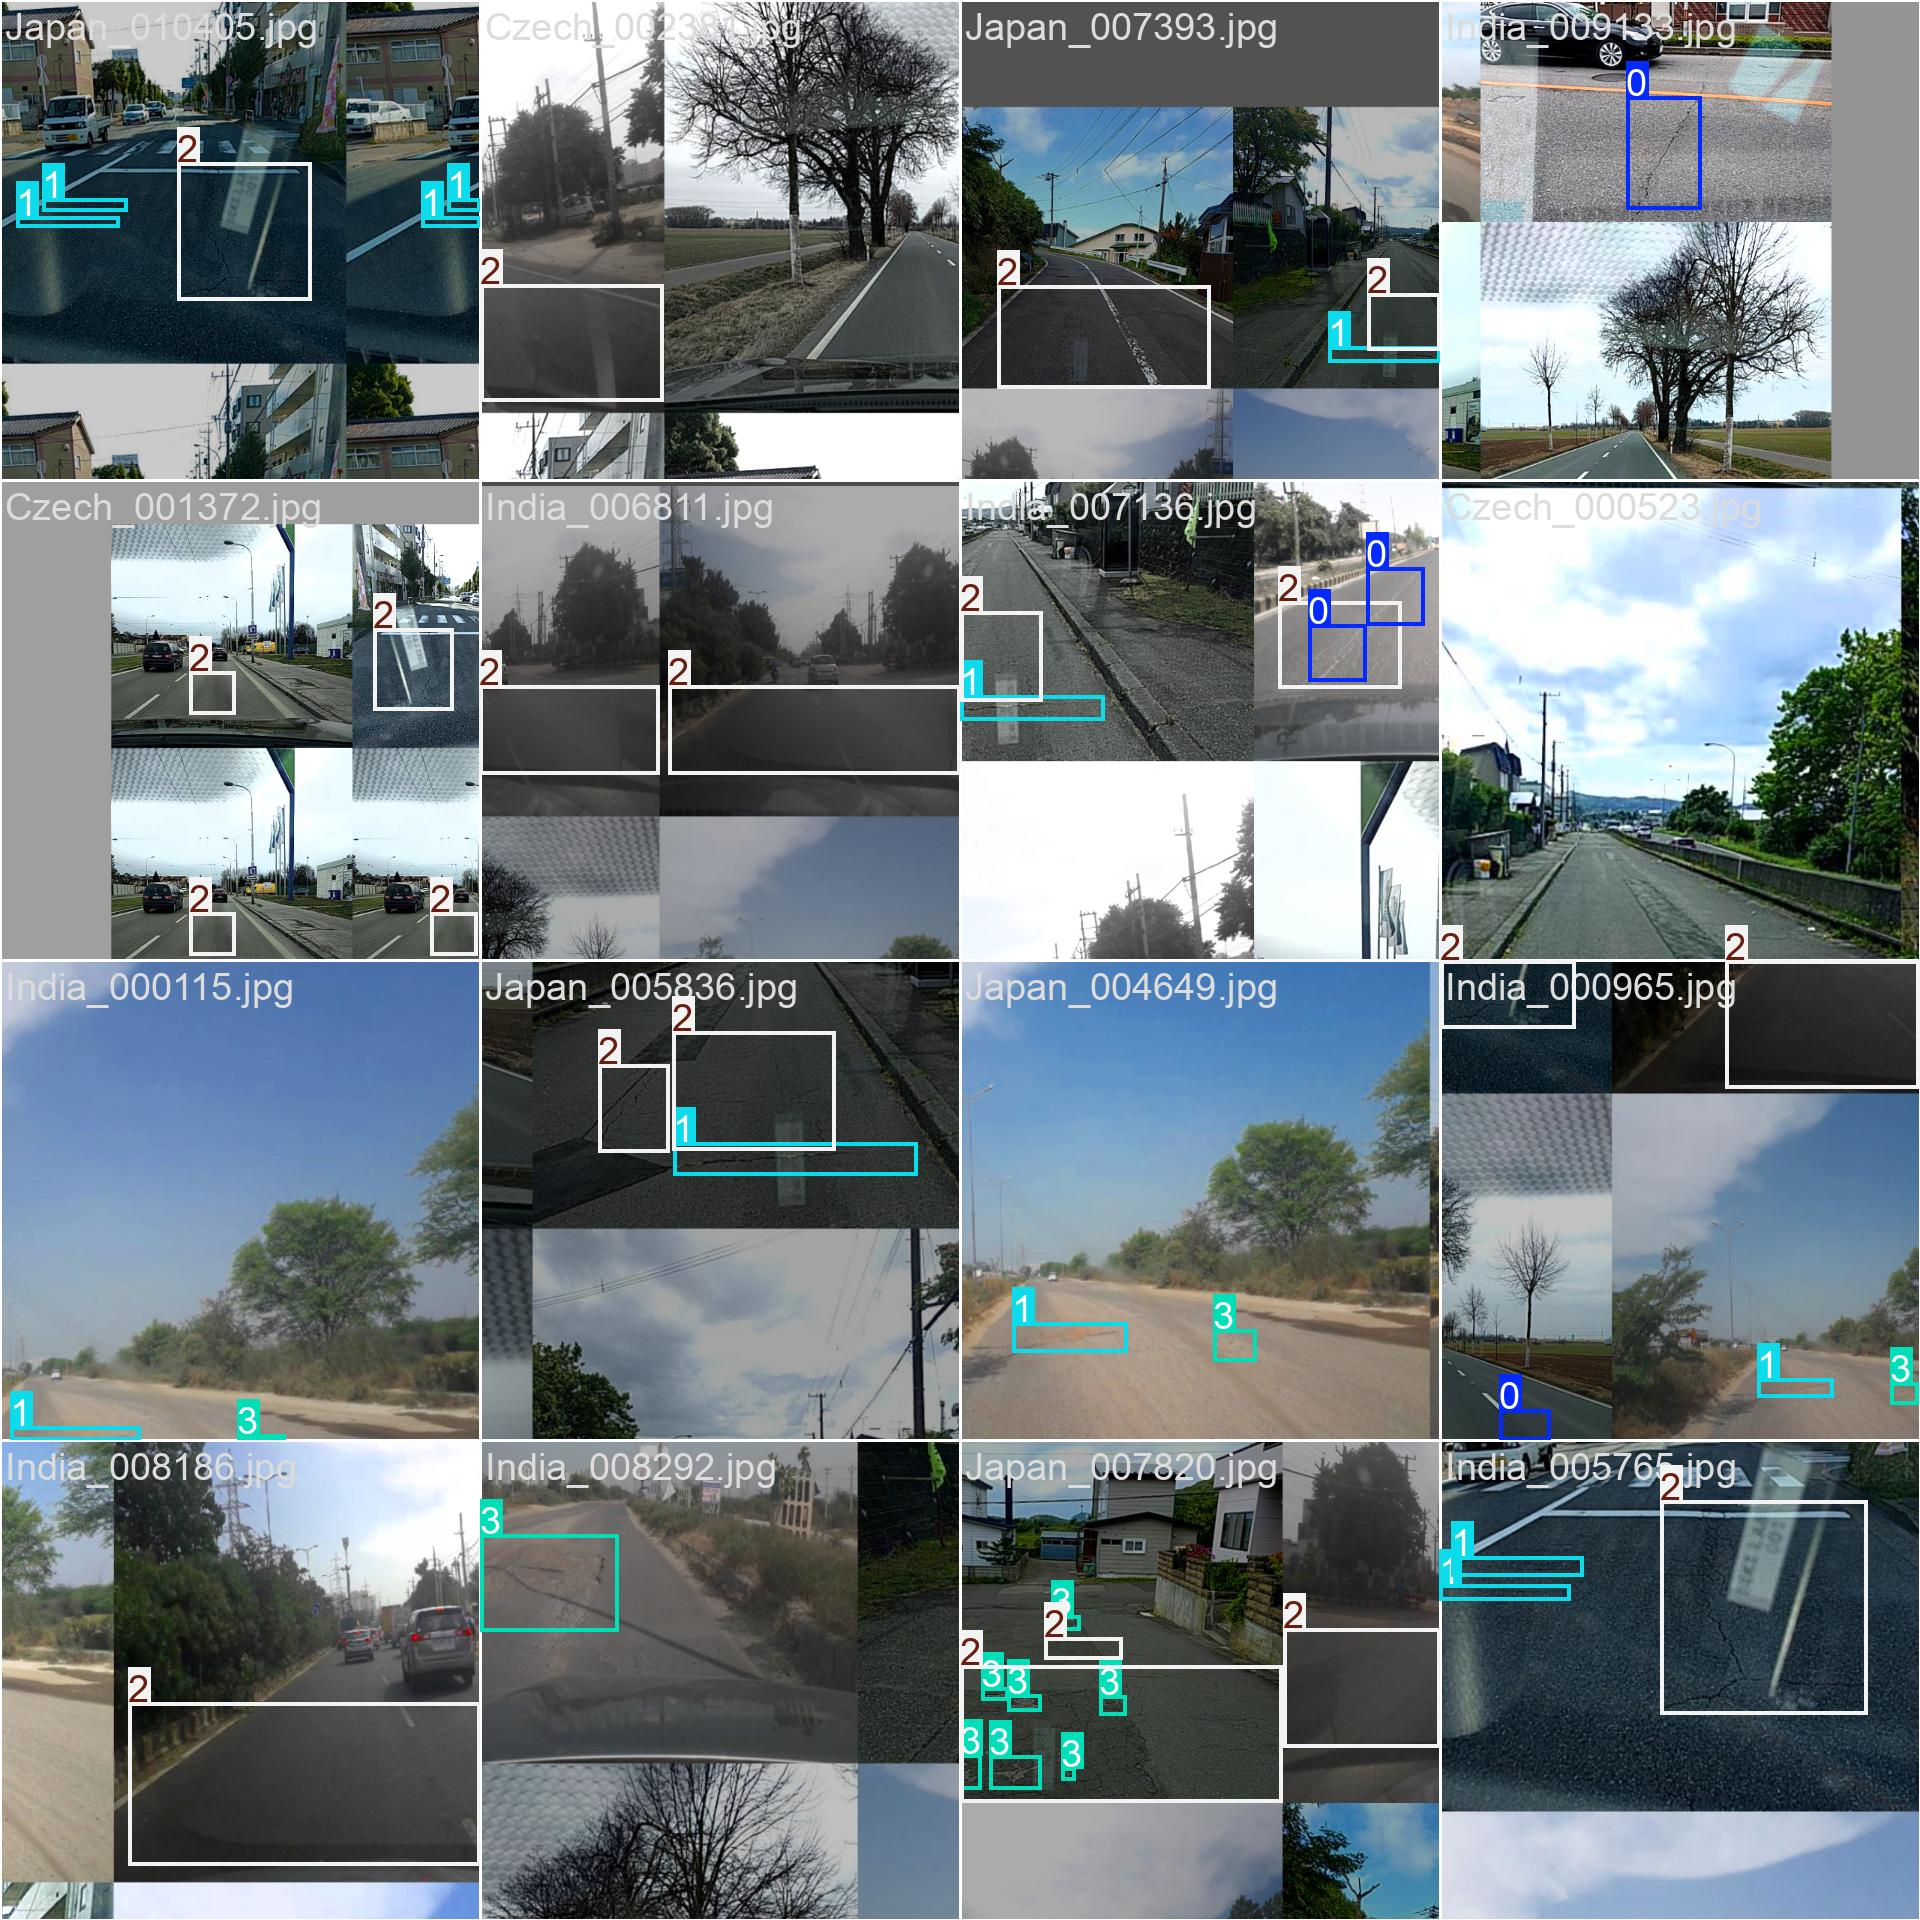

In [7]:
from pathlib import Path
from IPython.display import display, Image

run_dir = Path("/kaggle/working/runs/yolov8n_sample600")
batch_image = run_dir / "train_batch0.jpg"

assert batch_image.is_file(), f"Image not found: {batch_image}"
display(Image(filename=str(batch_image), width=1200))

Japan_005836


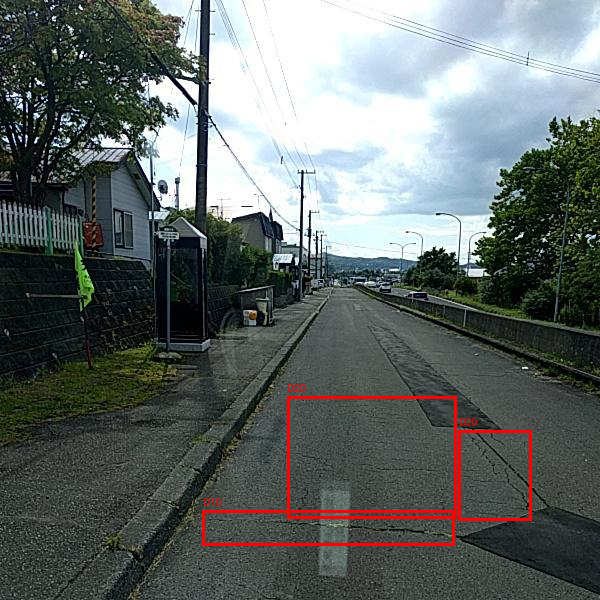

Japan_004649


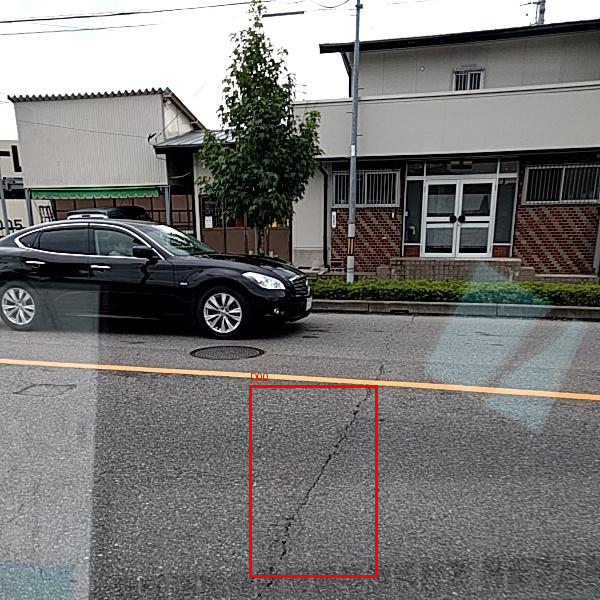

In [8]:
from pathlib import Path
from PIL import Image, ImageDraw
from IPython.display import display

root = Path("/kaggle/working/sample600/train")
classes = ["D00", "D10", "D20", "D40"]

for stem in ["Japan_005836", "Japan_004649"]:
    image = Image.open(root / "images" / f"{stem}.jpg").convert("RGB")
    draw = ImageDraw.Draw(image)
    w, h = image.size

    label = root / "labels" / f"{stem}.txt"

    for line in label.read_text().splitlines():
        if not line.strip():
            continue

        cls, cx, cy, bw, bh = map(float, line.split())
        box = [
            (cx - bw / 2) * w,
            (cy - bh / 2) * h,
            (cx + bw / 2) * w,
            (cy + bh / 2) * h,
        ]

        draw.rectangle(box, outline="red", width=3)
        draw.text((box[0], max(0, box[1] - 15)),
                  classes[int(cls)], fill="red")

    print(stem)
    display(image)

In [9]:
from pathlib import Path
import shutil
from IPython.display import FileLink, display

run_dir = Path("/kaggle/working/runs/yolov8n_sample600")
assert (run_dir / "weights/best.pt").is_file(), "Model file not found."

backup = Path("/kaggle/working/roadscan_backup")
backup.mkdir(exist_ok=True)

shutil.copytree(run_dir, backup / "training_results", dirs_exist_ok=True)

for name in ["data.yaml", "sample600_list.txt"]:
    source = Path("/kaggle/working") / name
    if source.is_file():
        shutil.copy2(source, backup / name)

shutil.make_archive(
    "/kaggle/working/roadscan_backup",
    "zip",
    root_dir=backup,
)

display(FileLink("/kaggle/working/roadscan_backup.zip"))

/kaggle/working/roadscan_backup.zip